# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [1]:
!git clone https://github.com/VinUni-AI20k/K4-Track-4-Day10-VisionLanguageModel.git

Cloning into 'K4-Track-4-Day10-VisionLanguageModel'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 34 (delta 3), reused 3 (delta 3), pack-reused 21 (from 1)
Receiving objects: 100% (34/34), 31.51 KiB | 3.50 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [2]:
%cd K4-Track-4-Day10-VisionLanguageModel

/kaggle/working/K4-Track-4-Day10-VisionLanguageModel


In [3]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-3a8ceae3-42c1-c381-7cdf-57f6823f3363)
GPU 1: Tesla T4 (UUID: GPU-05ceefcb-bcad-4a14-2a2e-dcc7e8e921a2)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 76.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 23.7 MB/s eta 0:00:00


In [4]:
# Kaggle credentials: use Colab Secrets; never hard-code credentials.
import os
from kaggle_secrets import UserSecretsClient

# Load Kaggle credentials from Kaggle Secrets
user_secrets = UserSecretsClient()

for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
    try:
        value = user_secrets.get_secret(key)
        if value:
            os.environ[key] = value
    except Exception as e:
        print(f"Could not load {key}: {e}")

## 1. Dữ liệu: tải và chia split

In [5]:
!python scripts/prepare_data.py --kaggle

Dataset URL: https://www.kaggle.com/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
License(s): MIT
100%|█████████████████████████████████████████| 185M/185M [00:01<00:00, 134MB/s]

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


train: 1422 images, 3515 boxes
val: 276 images, 639 boxes
test: 311 images, 583 boxes
session overlap train/val: 0
session overlap train/test: 0
session overlap val/test: 0


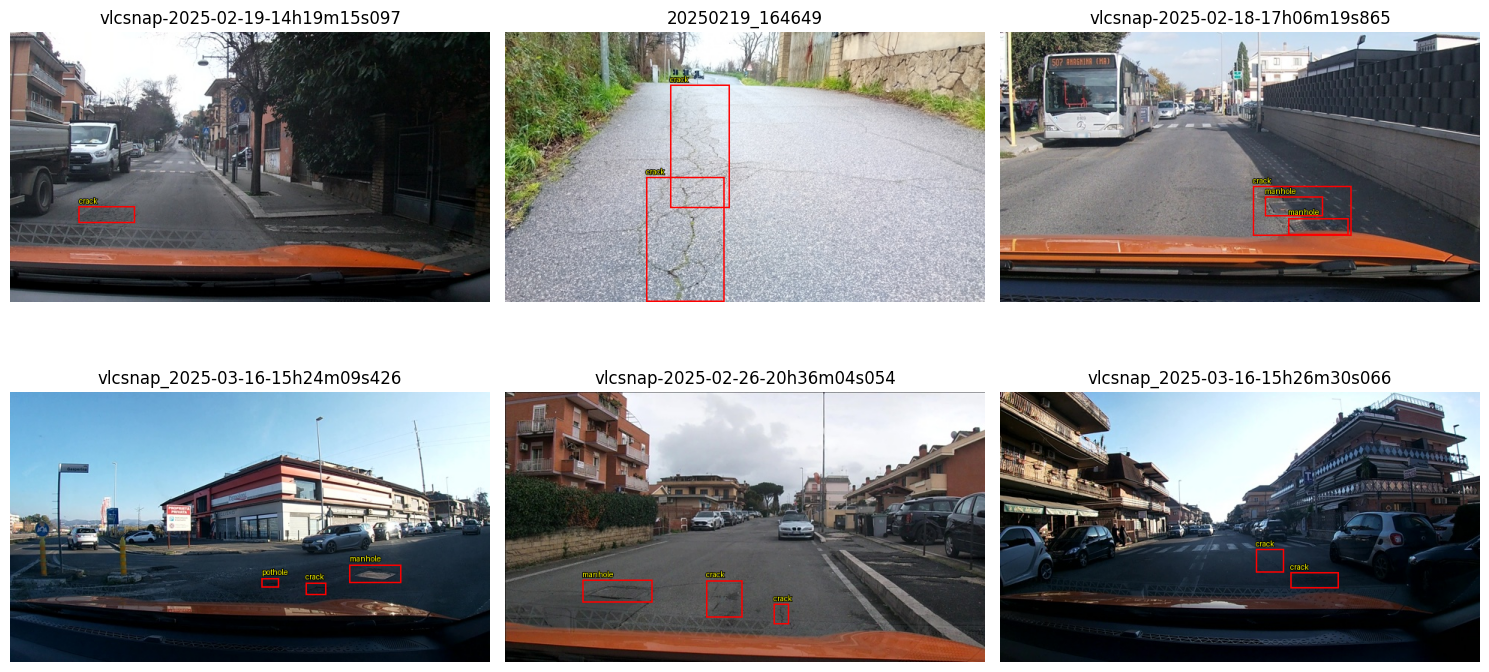

In [6]:
from pathlib import Path
import json, random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DATA_DIR = Path("data")
SPLIT_DIR = DATA_DIR / "splits"

def read_jsonl(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the data preparation cell first.")
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

splits = {name: read_jsonl(SPLIT_DIR / f"{name}.jsonl")
          for name in ("train", "val", "test")}
for name, rows in splits.items():
    n_boxes = sum(len(row.get("objects", [])) for row in rows)
    print(f"{name}: {len(rows)} images, {n_boxes} boxes")

# A session must belong to exactly one split to prevent near-duplicate leakage.
sessions_by_split = {
    name: {row.get("session") for row in rows if row.get("session") is not None}
    for name, rows in splits.items()
}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    overlap = sessions_by_split[a] & sessions_by_split[b]
    print(f"session overlap {a}/{b}: {len(overlap)}")
    assert not overlap, f"Session leakage between {a} and {b}: {list(overlap)[:5]}"

def resolve_image_path(relative_path):
    p = Path(relative_path)
    if p.exists():
        return p
    candidate = DATA_DIR / p
    if candidate.exists():
        return candidate
    raise FileNotFoundError(f"Image not found: {relative_path}")

def draw_sample(row, ax=None):
    image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
    draw = ImageDraw.Draw(image)
    W, H = image.size
    for obj in row.get("objects", []):
        xc, yc, w, h = obj["yolo"]
        box = ((xc-w/2)*W, (yc-h/2)*H, (xc+w/2)*W, (yc+h/2)*H)
        draw.rectangle(box, outline="red", width=max(2, W//320))
        draw.text((box[0], max(0, box[1]-14)), obj["label"], fill="yellow",
                  stroke_width=1, stroke_fill="black")
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(row.get("image_id", Path(row["image_path"]).name))
    return ax

sample_rows = random.sample(splits["train"], min(6, len(splits["train"])))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, row in zip(axes.flat, sample_rows):
    draw_sample(row, ax)
for ax in axes.flat[len(sample_rows):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

Classes: ('crack', 'manhole', 'pothole')
Prompt: Detect road damage in the image. Allowed classes: crack, manhole, pothole. Return only a JSON list. Each item must have keys "label" and "bbox_2d", where bbox_2d is [x1,y1,x2,y2] on the 0–1000 coordinate scale (0 is the left/top edge and 1000 is the right/bottom edge). Use only the allowed classes. If no damage is visible, return [].
Example answer: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]


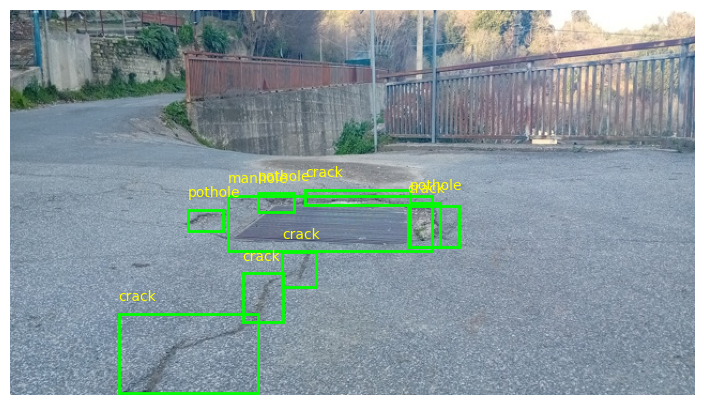

[{'label': 'crack', 'bbox_2d': [430, 467, 583, 506]},
 {'label': 'pothole', 'bbox_2d': [361, 475, 414, 522]},
 {'label': 'manhole', 'bbox_2d': [317, 481, 616, 625]},
 {'label': 'pothole', 'bbox_2d': [583, 500, 627, 614]},
 {'label': 'crack', 'bbox_2d': [580, 508, 655, 614]},
 {'label': 'pothole', 'bbox_2d': [259, 517, 311, 572]},
 {'label': 'crack', 'bbox_2d': [397, 628, 447, 717]},
 {'label': 'crack', 'bbox_2d': [339, 683, 398, 808]},
 {'label': 'crack', 'bbox_2d': [158, 789, 361, 994]}]

In [7]:
import json
from PIL import Image

# Derive the exact class names from the prepared labels instead of assuming them.
CLASSES = tuple(sorted({obj["label"] for row in splits["train"]
                        for obj in row.get("objects", [])}))
if not CLASSES:
    raise ValueError("No training labels found. Check data/splits/train.jsonl.")

PROMPT = (
    "Detect road damage in the image. Allowed classes: " + ", ".join(CLASSES) + ". "
    'Return only a JSON list. Each item must have keys "label" and "bbox_2d", '
    "where bbox_2d is [x1,y1,x2,y2] on the 0–1000 coordinate scale "
    "(0 is the left/top edge and 1000 is the right/bottom edge). "
    "Use only the allowed classes. If no damage is visible, return []."
)

def yolo_to_box(label, yolo):
    if label not in CLASSES:
        raise ValueError(f"Unknown label {label!r}; expected one of {CLASSES}")
    xc, yc, w, h = map(float, yolo)
    coords = [
        round((xc - w / 2) * 1000),
        round((yc - h / 2) * 1000),
        round((xc + w / 2) * 1000),
        round((yc + h / 2) * 1000),
    ]
    coords = [max(0, min(1000, int(v))) for v in coords]
    x1, y1, x2, y2 = coords
    if x2 < x1: x1, x2 = x2, x1
    if y2 < y1: y1, y2 = y2, y1
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects):
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    boxes.sort(key=lambda item: (item["bbox_2d"][1], item["bbox_2d"][0]))
    return json.dumps(boxes, separators=(",", ":"), ensure_ascii=False)

def verify_box_round_trip(row):
    image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
    W, H = image.size
    answer = json.loads(objects_to_answer(row.get("objects", [])))
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.imshow(image)
    for item in answer:
        x1, y1, x2, y2 = item["bbox_2d"]
        px = [x1*W/1000, y1*H/1000, x2*W/1000, y2*H/1000]
        ax.add_patch(plt.Rectangle((px[0], px[1]), px[2]-px[0], px[3]-px[1],
                                   fill=False, edgecolor="lime", linewidth=2))
        ax.text(px[0], max(0, px[1]-12), item["label"], color="yellow")
    ax.axis("off"); plt.show()
    image.close()
    return answer

print("Classes:", CLASSES)
print("Prompt:", PROMPT)
print("Example answer:", objects_to_answer(splits["train"][0].get("objects", [])))
verify_box_round_trip(splits["train"][0])

## 3. E0: zero-shot

In [8]:
import os, json, time, gc
from pathlib import Path
import torch
from PIL import Image
from tqdm.auto import tqdm

WORK_DIR = Path("work")
EVIDENCE_DIR = Path("report/evidence")
WORK_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

# Model loading / inference are expensive; set True when ready to run on a GPU.
RUN_E0 = True
MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

def load_base_model():
    from transformers import AutoProcessor, BitsAndBytesConfig
    from transformers import Qwen3VLForConditionalGeneration
    if not torch.cuda.is_available():
        raise RuntimeError("Qwen3-VL-4B 4-bit inference requires a CUDA GPU for this lab.")
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=["visual", "lm_head"],
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization, dtype=torch.float16,
        device_map={"": 0},
    )
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = "left"
    model.eval()
    return model, processor

def make_user_message(image, prompt=PROMPT):
    return {"role": "user", "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": prompt},
    ]}

@torch.inference_mode()
def predict_rows(model, processor, rows, output_path, batch_size=4, max_new_tokens=256):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    image_ids = [row["image_id"] for row in rows]
    if len(image_ids) != len(set(image_ids)):
        raise ValueError("Input rows contain duplicate image_id values.")

    written_count = 0
    with output_path.open("w", encoding="utf-8") as out_f:
        for start in tqdm(range(0, len(rows), batch_size), desc=output_path.name):
            batch = rows[start:start+batch_size]
            images = [Image.open(resolve_image_path(row["image_path"])).convert("RGB") for row in batch]
            try:
                # Each conversation must produce one generation, one per image.
                messages = [[make_user_message(image)] for image in images]
                inputs = processor.apply_chat_template(
                    messages, tokenize=True, add_generation_prompt=True,
                    return_dict=True, return_tensors="pt", padding=True,
                )
                inputs = {key: (value.to(model.device) if torch.is_tensor(value) else value)
                          for key, value in inputs.items()}
                generated = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
                prompt_len = inputs["input_ids"].shape[1]
                decoded = processor.batch_decode(generated[:, prompt_len:],
                                                  skip_special_tokens=True)
                if len(decoded) != len(batch):
                    raise RuntimeError(
                        f"Expected {len(batch)} generations, received {len(decoded)}."
                    )
                for row, raw in zip(batch, decoded):
                    out_f.write(json.dumps({"image_id": row["image_id"], "raw": raw},
                                           ensure_ascii=False) + "\n")
                    written_count += 1
            finally:
                for image in images:
                    image.close()

    if written_count != len(rows):
        raise RuntimeError(f"Wrote {written_count} predictions for {len(rows)} input images.")
    return output_path

if RUN_E0:
    model, processor = load_base_model()
    e0_path = predict_rows(model, processor, splits["test"], WORK_DIR / "e0.jsonl")
    print(f"Saved {e0_path}; first outputs:")
    for i, line in enumerate(e0_path.open(encoding="utf-8")):
        if i >= 5:
            break
        print(line.rstrip())
    del model, processor
    gc.collect(); torch.cuda.empty_cache()
else:
    print("E0 is implemented but not run. Set RUN_E0=True and execute this cell on a CUDA runtime.")

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

e0.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

Saved work/e0.jsonl; first outputs:
{"image_id": "vlcsnap-00200", "raw": "[{\"label\": \"manhole\", \"bbox_2d\": [917, 786, 1000, 824]}, {\"label\": \"manhole\", \"bbox_2d\": [759, 640, 845, 684]}]"}
{"image_id": "vlcsnap-00201", "raw": "[]"}
{"image_id": "vlcsnap-00202", "raw": "[{\"label\": \"manhole\", \"bbox_2d\": [317, 684, 393, 719]}, {\"label\": \"manhole\", \"bbox_2d\": [317, 684, 393, 719]}]"}
{"image_id": "vlcsnap-00203", "raw": "[]"}
{"image_id": "vlcsnap-00204", "raw": "[{\"label\": \"manhole\", \"bbox_2d\": [259, 632, 312, 660]}]"}


In [9]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.916 P=0.095 R=0.060 F1=0.074 CI95=0.049-0.104 meanIoU=0.614 FP/img=1.07
   pothole  P=0.277 R=0.107 F1=0.155
   crack    P=0.022 R=0.017 F1=0.019
   manhole  P=0.177 R=0.104 F1=0.131


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [10]:
import torch
from torch.nn.utils.rnn import pad_sequence

def encode_example(image, prompt, answer, processor):
    user = make_user_message(image, prompt)
    prompt_enc = processor.apply_chat_template(
        [user], tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt",
    )
    full_enc = processor.apply_chat_template(
        [user, {"role": "assistant", "content": answer}],
        tokenize=True, add_generation_prompt=False,
        return_dict=True, return_tensors="pt",
    )
    n = prompt_enc["input_ids"].shape[1]
    if not torch.equal(full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]):
        raise ValueError("Prompt token sequence is not a prefix of the full conversation.")
    result = {k: v for k, v in full_enc.items()}
    result["labels"] = full_enc["input_ids"].clone()
    result["labels"][:, :n] = -100
    return result

def collate_examples(batch, processor):
    # Text-like sequences are padded; image tensors/grid metadata are concatenated.
    pad_id = processor.tokenizer.pad_token_id
    if pad_id is None:
        pad_id = processor.tokenizer.eos_token_id
    sequence_keys = ("input_ids", "attention_mask", "mm_token_type_ids", "labels")
    result = {}
    max_len = max(item["input_ids"].shape[1] for item in batch)
    for key in sequence_keys:
        if not all(key in item for item in batch):
            continue
        tensors = []
        for item in batch:
            x = item[key].squeeze(0)
            pad_value = -100 if key == "labels" else (pad_id if key == "input_ids" else 0)
            if x.shape[0] < max_len:
                x = torch.nn.functional.pad(x, (0, max_len-x.shape[0]), value=pad_value)
            tensors.append(x)
        result[key] = torch.stack(tensors)
    for key in ("pixel_values", "image_grid_thw"):
        vals = [item[key] for item in batch if key in item]
        if vals:
            result[key] = torch.cat(vals, dim=0)
    return result

# Smoke-check one encoded example after the processor is loaded.
print("Encoding/collation functions defined. Run after loading the processor/model.")

Encoding/collation functions defined. Run after loading the processor/model.


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [11]:
import re
import torch
from peft import LoraConfig, get_peft_model

# Language-model targets: 36 layers × 7 modules = 252
LLM_PATTERN = re.compile(
    r"model\.language_model\.layers\.\d+\."
    r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|"
    r"mlp\.(?:gate_proj|up_proj|down_proj))$"
)

# Vision targets: 24 blocks × 4 modules = 96
VIT_PATTERN = re.compile(
    r"model\.visual\.blocks\.\d+\."
    r"(?:attn\.(?:qkv|proj)|"
    r"mlp\.(?:linear_fc1|linear_fc2))$"
)

PROJECTOR_MARKERS = (
    "visual.merger",
    "visual.deepstack_merger_list",
)


def keep_projectors_fp32(model):
    projector_modules = []
    for name, module in model.named_modules():
        parts = name.split(".")
        if "visual" not in parts:
            continue
        visual_index = parts.index("visual")
        tail = parts[visual_index + 1:]
        is_merger = len(tail) > 1 and tail[0] == "merger"
        is_deepstack_merger = (
            len(tail) > 2
            and tail[0] == "deepstack_merger_list"
            and tail[1].isdigit()
        )
        if is_merger or is_deepstack_merger:
            projector_modules.append((name, module))

    if not projector_modules:
        raise RuntimeError("No visual merger modules found to keep in FP32.")

    for name, module in projector_modules:
        original_forward = module.forward

        def fp32_forward(*args, _forward=original_forward, _module=module, _name=name, **kwargs):
            if not args or not torch.is_tensor(args[0]):
                return _forward(*args, **kwargs)
            output_dtype = args[0].dtype
            with torch.autocast(
                device_type=args[0].device.type,
                enabled=False,
            ):
                for param_name, param in _module.named_parameters(recurse=False):
                    if param.dtype != torch.float32:
                        param.data = param.data.float()
                try:
                    output = _forward(args[0].float(), *args[1:], **kwargs)
                finally:
                    for param_name, param in _module.named_parameters(recurse=False):
                        if param.dtype != torch.float32:
                            param.data = param.data.float()
            if torch.is_tensor(output):
                return output.to(dtype=output_dtype)
            return output

        module.forward = fp32_forward


def apply_setup(model, setup, r=16):
    setup = setup.upper()

    if setup not in {"E1", "E2", "E3"}:
        raise ValueError("setup must be E1, E2, or E3")

    # 1. Freeze all original model parameters.
    for param in model.parameters():
        param.requires_grad_(False)

    # Required for gradient checkpointing with frozen base weights.
    if hasattr(model, "enable_input_require_grads"):
        model.enable_input_require_grads()

    # 2. Validate the actual model module names.
    names = [name for name, _ in model.named_modules()]

    matched_llm = [
        name for name in names
        if LLM_PATTERN.fullmatch(name)
    ]

    matched_vit = (
        [
            name for name in names
            if VIT_PATTERN.fullmatch(name)
        ]
        if setup == "E3"
        else []
    )

    matched = matched_llm + matched_vit
    expected = 348 if setup == "E3" else 252

    print(
        f"{setup}: matched {len(matched)} target modules "
        f"(expected {expected})"
    )

    if len(matched) != expected:
        relevant = [
            name for name in names
            if "language_model.layers" in name
            or "visual.blocks" in name
        ]
        print("\nRelevant module names:")
        print("\n".join(relevant[:100]))

        raise ValueError(
            f"{setup}: expected {expected} target modules, "
            f"but found {len(matched)}. No LoRA adapters were added."
        )

    # 3. Configure LoRA targets.
    llm_targets = (
        r".*model\.language_model\.layers\.\d+\."
        r"(?:self_attn\.(?:q_proj|k_proj|v_proj|o_proj)|"
        r"mlp\.(?:gate_proj|up_proj|down_proj))"
    )

    if setup == "E3":
        target_modules = (
            r"(?:"
            + llm_targets
            + r"|.*model\.visual\.blocks\.\d+\."
            r"(?:attn\.(?:qkv|proj)|"
            r"mlp\.(?:linear_fc1|linear_fc2))"
            + r")"
        )
    else:
        target_modules = llm_targets

    peft_model = get_peft_model(
        model,
        LoraConfig(
            r=r,
            lora_alpha=2 * r,
            lora_dropout=0.05,
            bias="none",
            target_modules=target_modules,
            task_type="CAUSAL_LM",
        ),
    )

    # 4. E2/E3: train the visual projectors in FP32.
    # E1 leaves these parameters frozen.
    projector_params = []

    if setup in {"E2", "E3"}:
        for name, param in peft_model.named_parameters():
            if any(marker in name for marker in PROJECTOR_MARKERS):
                param.data = param.data.float()
                param.requires_grad_(True)
                projector_params.append(name)

        if not projector_params:
            raise RuntimeError(
                f"{setup}: no projector parameters matched "
                f"{PROJECTOR_MARKERS}. Inspect named_parameters() "
                "before training."
            )

        non_fp32 = [
            name for name, param in peft_model.named_parameters()
            if any(marker in name for marker in PROJECTOR_MARKERS)
            and param.requires_grad
            and param.dtype != torch.float32
        ]

        if non_fp32:
            raise RuntimeError(
                "Some trainable projector parameters are not FP32: "
                + ", ".join(non_fp32[:10])
            )

        print(
            f"Trainable projector parameter tensors: "
            f"{len(projector_params)}"
        )

    # 4.5. Keep all trainable parameters in FP32.
    # Frozen base-model weights retain their original dtype.
    for name, param in peft_model.named_parameters():
        if param.requires_grad and param.dtype != torch.float32:
            param.data = param.data.float()

    # Verify the trainable parameter dtypes.
    non_fp32_trainable = [
        (name, str(param.dtype))
        for name, param in peft_model.named_parameters()
        if param.requires_grad and param.dtype != torch.float32
    ]

    if non_fp32_trainable:
        raise RuntimeError(
            "Found trainable parameters that are not FP32: "
            + ", ".join(
                f"{name} ({dtype})"
                for name, dtype in non_fp32_trainable[:10]
            )
        )

    if setup in {"E2", "E3"}:
        keep_projectors_fp32(peft_model)

    # 5. Report trainable parameter count and dtype distribution.
    trainable = sum(
        param.numel()
        for param in peft_model.parameters()
        if param.requires_grad
    )

    total = sum(
        param.numel()
        for param in peft_model.parameters()
    )

    trainable_dtypes = {}
    for param in peft_model.parameters():
        if param.requires_grad:
            key = str(param.dtype)
            trainable_dtypes[key] = (
                trainable_dtypes.get(key, 0) + param.numel()
            )

    print("Trainable parameter dtypes:", trainable_dtypes)
    print(
        f"Trainable parameters: {trainable:,} / {total:,} "
        f"({100 * trainable / total:.4f}%)"
    )

    return peft_model, {
        "matched_modules": len(matched),
        "trainable_params": trainable,
    }

## 6. Vòng huấn luyện

In [12]:
import math, time, json, gc, copy
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

TRAIN_CONFIG = {
    "max_steps": 300, "batch_size": 2, "grad_accum": 4,
    "learning_rate": 2e-4, "weight_decay": 0.0, "warmup_ratio": 0.05,
    "save_every": 100, "max_grad_norm": 1.0, "num_workers": 0,
}
RUN_TRAINING = True  # Set True after confirming GPU memory and data availability.

class RoadDamageDataset(Dataset):
    def __init__(self, rows, processor):
        self.rows = rows
        self.processor = processor

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        image = Image.open(resolve_image_path(row["image_path"])).convert("RGB")
        try:
            answer = objects_to_answer(row.get("objects", []))
            encoded = encode_example(image, PROMPT, answer, self.processor)
        finally:
            image.close()
        return encoded

def save_projector_weights(model, path):
    state = {name: p.detach().float().cpu()
             for name, p in model.named_parameters()
             if any(marker in name for marker in PROJECTOR_MARKERS)}
    torch.save(state, path)


def train_setup(setup, model, processor, train_rows, config=TRAIN_CONFIG, rank=16):
    setup = setup.upper()
    setup_dir = Path("work") / setup.lower()
    setup_dir.mkdir(parents=True, exist_ok=True)

    # Apply the selected experiment setup (E1, E2, or E3).
    peft_model, info = apply_setup(model, setup, r=rank)
    peft_model.config.use_cache = False

    # Enable gradient checkpointing.
    try:
        peft_model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False}
        )
    except TypeError:
        peft_model.gradient_checkpointing_enable()

    # IMPORTANT:
    # Convert every trainable parameter to FP32 AFTER apply_setup().
    # Frozen base-model parameters may remain FP16.
    for name, param in peft_model.named_parameters():
        if param.requires_grad and param.dtype != torch.float32:
            param.data = param.data.to(dtype=torch.float32)

    trainable_params = [
        param for param in peft_model.parameters()
        if param.requires_grad
    ]

    if not trainable_params:
        raise RuntimeError(f"{setup}: no trainable parameters found.")

    non_fp32_params = [
        name for name, param in peft_model.named_parameters()
        if param.requires_grad and param.dtype != torch.float32
    ]
    if non_fp32_params:
        raise RuntimeError(
            f"{setup}: trainable parameters are not FP32: "
            + ", ".join(non_fp32_params[:20])
        )

    dtype_counts = {}
    for param in trainable_params:
        dtype = str(param.dtype)
        dtype_counts[dtype] = dtype_counts.get(dtype, 0) + param.numel()

    print(f"{setup}: trainable parameter dtypes = {dtype_counts}")
    print(f"{setup}: trainable parameter tensors = {len(trainable_params)}")

    # Dataset and DataLoader.
    dataset = RoadDamageDataset(train_rows, processor)
    loader = DataLoader(
        dataset,
        batch_size=config["batch_size"],
        shuffle=True,
        collate_fn=lambda batch: collate_examples(batch, processor),
        num_workers=config["num_workers"],
    )

    # Optimizer and learning-rate scheduler.
    optimizer = AdamW(
        trainable_params,
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )

    max_steps = config["max_steps"]
    warmup_steps = max(1, int(max_steps * config["warmup_ratio"]))

    def lr_lambda(step):
        if step < warmup_steps:
            return max(1e-8, (step + 1) / warmup_steps)

        progress = min(
            1.0,
            (step - warmup_steps) / max(1, max_steps - warmup_steps),
        )
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    # FP16 mixed-precision training with gradient scaling.
    use_cuda = torch.cuda.is_available()
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    device = next(peft_model.parameters()).device


    peft_model.train()

    optimizer.zero_grad(set_to_none=True)


    step = 0
    micro_step = 0
    running_loss = 0.0
    losses = []
    start_time = time.time()

    if use_cuda:
        torch.cuda.reset_peak_memory_stats()

    while step < max_steps:
        for batch in loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }
            # Frozen base-model layers can run in FP16.
            # Trainable parameters are kept in FP32.
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_cuda,
            ):
                loss = peft_model(**batch).loss
                scaled_loss = loss / config["grad_accum"]

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Non-finite loss at optimizer step {step}: "
                    f"{loss.item()}"
                )

            # Backpropagate the scaled loss.
            scaler.scale(scaled_loss).backward()
            running_loss += float(loss.detach())
            micro_step += 1

            if micro_step % config["grad_accum"] != 0:
                continue

            # AMP can produce FP16 gradients for FP32 parameters in parts
            # of the vision path. Restore the parameter dtype before
            # GradScaler unscales gradients and the optimizer updates them.
            converted_grads = []
            bad_parameter_dtypes = []
            for name, param in peft_model.named_parameters():
                if not param.requires_grad or param.grad is None:
                    continue
                if param.dtype != torch.float32:
                    bad_parameter_dtypes.append((name, param.dtype, param.grad.dtype))
                if param.grad.dtype != param.dtype:
                    param.grad = param.grad.to(dtype=param.dtype)
                    converted_grads.append(name)
            if bad_parameter_dtypes:
                details = "\n".join(
                    f"  {name}: parameter={param_dtype}, gradient={grad_dtype}"
                    for name, param_dtype, grad_dtype in bad_parameter_dtypes
                )
                raise RuntimeError(
                    f"{setup}: trainable parameter dtype changed during "
                    f"forward/backward; expected FP32. Exact parameters:\n{details}"
                )

            if converted_grads and step == 0:
                print(
                    f"{setup}: converted {len(converted_grads)} trainable gradients to FP32 before unscaling."
                )

            # Unscale, clip gradients, and update parameters.
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                trainable_params,
                config["max_grad_norm"],
            )

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

            step += 1

            mean_loss = running_loss / config["grad_accum"]
            losses.append({
                "step": step,
                "loss": mean_loss,
                "lr": scheduler.get_last_lr()[0],
            })
            running_loss = 0.0

            if step % 10 == 0:
                print(
                    f"{setup} step {step}/{max_steps} "
                    f"loss={mean_loss:.4f}"
                )

            # Save periodic checkpoints.
            if step % config["save_every"] == 0 or step == max_steps:
                ckpt = setup_dir / f"checkpoint-{step}"
                ckpt.mkdir(parents=True, exist_ok=True)

                peft_model.save_pretrained(ckpt)

                if setup in {"E2", "E3"}:
                    save_projector_weights(
                        peft_model,
                        ckpt / "extra_trainable.pt",
                    )

                with (ckpt / "losses.json").open(
                    "w", encoding="utf-8"
                ) as f:
                    json.dump(losses, f, indent=2)

            if step >= max_steps:
                break

    # Collect training statistics.
    elapsed = (time.time() - start_time) / 60

    peak_vram = (
        torch.cuda.max_memory_allocated() / (1024 ** 3)
        if use_cuda else 0.0
    )

    run_info = {
        **info,
        "setup": setup,
        "trainable_params": info["trainable_params"],
        "peak_vram_gb": round(peak_vram, 3),
        "train_minutes": round(elapsed, 2),
        "steps": step,
        "final_loss": losses[-1]["loss"] if losses else None,
    }

    # Save the final LoRA adapter and projector weights.
    final_dir = setup_dir / "final"
    final_dir.mkdir(parents=True, exist_ok=True)
    peft_model.save_pretrained(final_dir)

    if setup in {"E2", "E3"}:
        save_projector_weights(
            peft_model,
            final_dir / "extra_trainable.pt",
        )

    # Also save final loss history and run.json for result-check cells.
    with (setup_dir / "checkpoint-300" / "losses.json").open(
        "w", encoding="utf-8"
    ) as f:
        json.dump(losses, f, indent=2)

    with (setup_dir / "run.json").open("w", encoding="utf-8") as f:
        json.dump(run_info, f, indent=2)

    print(f"{setup}: training finished.")
    print(json.dumps(run_info, indent=2))

    return peft_model, run_info, losses

def run_one_setup(setup_name):
    """Train only one setup from a fresh base-model instance."""
    base_model = None
    trained_model = None
    try:
        base_model, processor = load_base_model()
        trained_model, run_info, losses = train_setup(
            setup_name, base_model, processor, splits["train"]
        )
        return run_info, losses
    finally:
        del trained_model
        del base_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# The former combined E1/E2/E3 runner is intentionally disabled.
# Do not uncomment this loop: run the individual setup cells below instead.
# for setup_name in ("E1", "E2", "E3"):
#     run_one_setup(setup_name)


### Train E1

Run only when you intentionally want to train or retrain E1.

In [13]:
# Train E1 ONLY. This loads a fresh base model and runs E1 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E1.
E1_result, E1_losses = run_one_setup("E1")
print("E1 completed:", E1_result)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E1: matched 252 target modules (expected 252)
Trainable parameter dtypes: {'torch.float32': 33030144}
Trainable parameters: 33,030,144 / 2,448,667,136 (1.3489%)
E1: trainable parameter dtypes = {'torch.float32': 33030144}
E1: trainable parameter tensors = 504


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


E1 step 10/300 loss=0.8445
E1 step 20/300 loss=0.6822
E1 step 30/300 loss=0.6815
E1 step 40/300 loss=0.6553
E1 step 50/300 loss=0.6501
E1 step 60/300 loss=0.6068
E1 step 70/300 loss=0.6525
E1 step 80/300 loss=0.6345
E1 step 90/300 loss=0.5926
E1 step 100/300 loss=0.6165
E1 step 110/300 loss=0.6218
E1 step 120/300 loss=0.5867
E1 step 130/300 loss=0.6707
E1 step 140/300 loss=0.6064
E1 step 150/300 loss=0.6086
E1 step 160/300 loss=0.5795
E1 step 170/300 loss=0.5857
E1 step 180/300 loss=0.5802
E1 step 190/300 loss=0.5683
E1 step 200/300 loss=0.5549
E1 step 210/300 loss=0.5460
E1 step 220/300 loss=0.6215
E1 step 230/300 loss=0.5871
E1 step 240/300 loss=0.6406
E1 step 250/300 loss=0.5966
E1 step 260/300 loss=0.5438
E1 step 270/300 loss=0.5615
E1 step 280/300 loss=0.5340
E1 step 290/300 loss=0.5917
E1 step 300/300 loss=0.5539
E1: training finished.
{
  "matched_modules": 252,
  "trainable_params": 33030144,
  "setup": "E1",
  "peak_vram_gb": 5.868,
  "train_minutes": 46.03,
  "steps": 300,
  

### E1 — Check existing results

This cell only inspects saved E1 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [14]:

from pathlib import Path
import json

setup_dir = Path("work/e1")
run_file = setup_dir / "run.json"
print("E1 saved-run check")

if not run_file.exists():
    print(f"No saved E1 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE1 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E1 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

E1 saved-run check
Run metadata:
{
  "matched_modules": 252,
  "trainable_params": 33030144,
  "setup": "E1",
  "peak_vram_gb": 5.868,
  "train_minutes": 46.03,
  "steps": 300,
  "final_loss": 0.5538677349686623
}

Checkpoint 100: present
  adapter config: True

Checkpoint 200: present
  adapter config: True

Checkpoint 300: present
  adapter config: True

Final adapter directory: present
Final adapter config: True

Saved loss records: 300
First loss: {'step': 1, 'loss': 1.1101745069026947, 'lr': 2.6666666666666667e-05}
Last loss:  {'step': 300, 'loss': 0.5538677349686623, 'lr': 0.0}

E1 loss history (every 10 steps):
E1 step 10/300 loss=0.8445
E1 step 20/300 loss=0.6822
E1 step 30/300 loss=0.6815
E1 step 40/300 loss=0.6553
E1 step 50/300 loss=0.6501
E1 step 60/300 loss=0.6068
E1 step 70/300 loss=0.6525
E1 step 80/300 loss=0.6345
E1 step 90/300 loss=0.5926
E1 step 100/300 loss=0.6165
E1 step 110/300 loss=0.6218
E1 step 120/300 loss=0.5867
E1 step 130/300 loss=0.6707
E1 step 140/300 los

### Train E2

Run only when you intentionally want to train or retrain E2.

In [15]:
# Train E2 ONLY. This loads a fresh base model and runs E2 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E2.
E2_result, E2_losses = run_one_setup("E2")
print("E2 completed:", E2_result)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E2: matched 252 target modules (expected 252)
Trainable projector parameter tensors: 24
Trainable parameter dtypes: {'torch.float32': 87609344}
Trainable parameters: 87,609,344 / 2,448,667,136 (3.5778%)
E2: trainable parameter dtypes = {'torch.float32': 87609344}
E2: trainable parameter tensors = 528
E2: converted 8 trainable gradients to FP32 before unscaling.
E2 step 10/300 loss=0.8570
E2 step 20/300 loss=0.8239
E2 step 30/300 loss=0.8066
E2 step 40/300 loss=0.7415
E2 step 50/300 loss=0.7179
E2 step 60/300 loss=0.7344
E2 step 70/300 loss=0.7376
E2 step 80/300 loss=0.7161
E2 step 90/300 loss=0.7412
E2 step 100/300 loss=0.7416
E2 step 110/300 loss=0.7370
E2 step 120/300 loss=0.7373
E2 step 130/300 loss=0.6898
E2 step 140/300 loss=0.7601
E2 step 150/300 loss=0.6839
E2 step 160/300 loss=0.7027
E2 step 170/300 loss=0.7758
E2 step 180/300 loss=0.7055
E2 step 190/300 loss=0.7041
E2 step 200/300 loss=0.6450
E2 step 210/300 loss=0.6837
E2 step 220/300 loss=0.7122
E2 step 230/300 loss=0.6798
E

### E2 — Check existing results

This cell only inspects saved E2 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [16]:

from pathlib import Path
import json

setup_dir = Path("work/e2")
run_file = setup_dir / "run.json"
print("E2 saved-run check")

if not run_file.exists():
    print(f"No saved E2 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")
            print(f"  projector weights: {(ckpt / 'extra_trainable.pt').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")
    print(f"Final projector weights: {(final_dir / 'extra_trainable.pt').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE2 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E2 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

E2 saved-run check
Run metadata:
{
  "matched_modules": 252,
  "trainable_params": 87609344,
  "setup": "E2",
  "peak_vram_gb": 6.074,
  "train_minutes": 45.45,
  "steps": 300,
  "final_loss": 0.7007148414850235
}

Checkpoint 100: present
  adapter config: True
  projector weights: True

Checkpoint 200: present
  adapter config: True
  projector weights: True

Checkpoint 300: present
  adapter config: True
  projector weights: True

Final adapter directory: present
Final adapter config: True
Final projector weights: True

Saved loss records: 300
First loss: {'step': 1, 'loss': 1.1591532826423645, 'lr': 2.6666666666666667e-05}
Last loss:  {'step': 300, 'loss': 0.7007148414850235, 'lr': 0.0}

E2 loss history (every 10 steps):
E2 step 10/300 loss=0.8570
E2 step 20/300 loss=0.8239
E2 step 30/300 loss=0.8066
E2 step 40/300 loss=0.7415
E2 step 50/300 loss=0.7179
E2 step 60/300 loss=0.7344
E2 step 70/300 loss=0.7376
E2 step 80/300 loss=0.7161
E2 step 90/300 loss=0.7412
E2 step 100/300 loss=0.

### Train E3

Run only when you intentionally want to train or retrain E3.

In [17]:
# Train E3 ONLY. This loads a fresh base model and runs E3 for 300 optimizer steps.
# Run this cell only if you intend to train/retrain E3.
E3_result, E3_losses = run_one_setup("E3")
print("E3 completed:", E3_result)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E3: matched 348 target modules (expected 348)
Trainable projector parameter tensors: 24
Trainable parameter dtypes: {'torch.float32': 93900800}
Trainable parameters: 93,900,800 / 2,454,958,592 (3.8249%)
E3: trainable parameter dtypes = {'torch.float32': 93900800}
E3: trainable parameter tensors = 720
E3: converted 8 trainable gradients to FP32 before unscaling.


/tmp/ipykernel_23/1795303294.py:210: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


E3 step 10/300 loss=0.8224
E3 step 20/300 loss=0.8486
E3 step 30/300 loss=0.8292
E3 step 40/300 loss=0.7806
E3 step 50/300 loss=0.7678
E3 step 60/300 loss=0.7168
E3 step 70/300 loss=0.7388
E3 step 80/300 loss=0.7282
E3 step 90/300 loss=0.6821
E3 step 100/300 loss=0.6489
E3 step 110/300 loss=0.7170
E3 step 120/300 loss=0.6978
E3 step 130/300 loss=0.6997
E3 step 140/300 loss=0.6837
E3 step 150/300 loss=0.7525
E3 step 160/300 loss=0.6898
E3 step 170/300 loss=0.6632
E3 step 180/300 loss=0.7271
E3 step 190/300 loss=0.6757
E3 step 200/300 loss=0.6681
E3 step 210/300 loss=0.6898
E3 step 220/300 loss=0.6753
E3 step 230/300 loss=0.6744
E3 step 240/300 loss=0.6623
E3 step 250/300 loss=0.6534
E3 step 260/300 loss=0.6747
E3 step 270/300 loss=0.6415
E3 step 280/300 loss=0.7037
E3 step 290/300 loss=0.6655
E3 step 300/300 loss=0.6357
E3: training finished.
{
  "matched_modules": 348,
  "trainable_params": 93900800,
  "setup": "E3",
  "peak_vram_gb": 6.309,
  "train_minutes": 54.32,
  "steps": 300,
  

### E3 — Check existing results

This cell only inspects saved E3 metadata, checkpoints, adapters, projector weights, and loss history. It does not load the base model or train.

In [18]:

from pathlib import Path
import json

setup_dir = Path("work/e3")
run_file = setup_dir / "run.json"
print("E3 saved-run check")

if not run_file.exists():
    print(f"No saved E3 run metadata found at {run_file}.")
    print("This cell does not train or modify any model.")
else:
    result = json.loads(run_file.read_text(encoding="utf-8"))
    print("Run metadata:")
    print(json.dumps(result, indent=2))

    for step in (100, 200, 300):
        ckpt = setup_dir / f"checkpoint-{step}"
        print(f"\nCheckpoint {step}: {'present' if ckpt.exists() else 'missing'}")
        if ckpt.exists():
            print(f"  adapter config: {(ckpt / 'adapter_config.json').exists()}")
            print(f"  projector weights: {(ckpt / 'extra_trainable.pt').exists()}")

    final_dir = setup_dir / "final"
    print(f"\nFinal adapter directory: {'present' if final_dir.exists() else 'missing'}")
    print(f"Final adapter config: {(final_dir / 'adapter_config.json').exists()}")
    print(f"Final projector weights: {(final_dir / 'extra_trainable.pt').exists()}")

    loss_file = setup_dir / "checkpoint-300" / "losses.json"
    if loss_file.exists():
        losses = json.loads(loss_file.read_text(encoding="utf-8"))
        print(f"\nSaved loss records: {len(losses)}")
        if losses:
            print(f"First loss: {losses[0]}")
            print(f"Last loss:  {losses[-1]}")

            print("\nE3 loss history (every 10 steps):")
            for item in losses:
                if item["step"] % 10 == 0:
                    print(f"E3 step {item['step']}/300 loss={item['loss']:.4f}")
    else:
        print(f"\nLoss history not found at {loss_file}.")

E3 saved-run check
Run metadata:
{
  "matched_modules": 348,
  "trainable_params": 93900800,
  "setup": "E3",
  "peak_vram_gb": 6.309,
  "train_minutes": 54.32,
  "steps": 300,
  "final_loss": 0.6357054859399796
}

Checkpoint 100: present
  adapter config: True
  projector weights: True

Checkpoint 200: present
  adapter config: True
  projector weights: True

Checkpoint 300: present
  adapter config: True
  projector weights: True

Final adapter directory: present
Final adapter config: True
Final projector weights: True

Saved loss records: 300
First loss: {'step': 1, 'loss': 1.09187713265419, 'lr': 2.6666666666666667e-05}
Last loss:  {'step': 300, 'loss': 0.6357054859399796, 'lr': 0.0}

E3 loss history (every 10 steps):
E3 step 10/300 loss=0.8224
E3 step 20/300 loss=0.8486
E3 step 30/300 loss=0.8292
E3 step 40/300 loss=0.7806
E3 step 50/300 loss=0.7678
E3 step 60/300 loss=0.7168
E3 step 70/300 loss=0.7388
E3 step 80/300 loss=0.7282
E3 step 90/300 loss=0.6821
E3 step 100/300 loss=0.64

## 7. Suy luận và chấm E1–E3

In [19]:
from peft import PeftModel

RUN_E123_INFERENCE = True  # Set True after training checkpoints exist.

def load_trained_setup(setup, checkpoint="final"):
    base_model, proc = load_base_model()
    adapter_dir = Path("work") / setup.lower() / checkpoint
    if not adapter_dir.exists():
        raise FileNotFoundError(f"Adapter checkpoint not found: {adapter_dir}")
    tuned = PeftModel.from_pretrained(base_model, adapter_dir, is_trainable=False)
    extra_path = adapter_dir / "extra_trainable.pt"
    if extra_path.exists():
        extra = torch.load(extra_path, map_location="cpu", weights_only=True)
        current = dict(tuned.named_parameters())
        missing = [name for name in extra if name not in current]
        if missing:
            raise KeyError(f"Projector parameters missing when restoring: {missing[:5]}")
        with torch.no_grad():
            for name, tensor in extra.items():
                current[name].copy_(tensor.to(device=current[name].device, dtype=current[name].dtype))
    tuned.eval()
    return tuned, proc

if RUN_E123_INFERENCE:
    for setup_name in ("E1", "E2", "E3"):
        tuned_model, tuned_processor = load_trained_setup(setup_name)
        # predict_rows uses the global processor; set it to the matching processor.
        processor = tuned_processor
        pred_path = predict_rows(tuned_model, processor, splits["test"],
                                 WORK_DIR / f"{setup_name.lower()}.jsonl")
        run_meta_path = Path("work") / setup_name.lower() / "run.json"
        meta = json.loads(run_meta_path.read_text()) if run_meta_path.exists() else {}
        import subprocess, sys
        cmd = [sys.executable, "scripts/score.py", "--pred", str(pred_path),
               "--name", setup_name, "--out", f"report/evidence/{setup_name.lower()}.json",
               "--meta", f"trainable_params={meta.get('trainable_params', 0)}",
               "--meta", f"peak_vram_gb={meta.get('peak_vram_gb', 0)}",
               "--meta", f"train_minutes={meta.get('train_minutes', 0)}"]
        subprocess.run(cmd, check=True)
        del tuned_model; gc.collect(); torch.cuda.empty_cache()
else:
    print("E1–E3 inference/scoring is implemented. Set RUN_E123_INFERENCE=True after training.")

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

e1.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

E1 [test] n=311 valid=0.990 P=0.238 R=0.256 F1=0.246 CI95=0.212-0.283 meanIoU=0.670 FP/img=1.53
   pothole  P=0.129 R=0.132 F1=0.131
   crack    P=0.167 R=0.227 F1=0.193
   manhole  P=0.684 R=0.399 F1=0.504


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

E2 [test] n=311 valid=0.887 P=0.086 R=0.096 F1=0.091 CI95=0.067-0.117 meanIoU=0.608 FP/img=1.92
   pothole  P=0.429 R=0.074 F1=0.127
   crack    P=0.022 R=0.040 F1=0.028
   manhole  P=0.438 R=0.215 F1=0.288


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

e3.jsonl:   0%|          | 0/78 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transform

E3 [test] n=311 valid=0.859 P=0.055 R=0.074 F1=0.063 CI95=0.045-0.082 meanIoU=0.618 FP/img=2.36
   pothole  P=0.060 R=0.099 F1=0.075
   crack    P=0.039 R=0.070 F1=0.050
   manhole  P=0.333 R=0.061 F1=0.104


## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [20]:
# E4 rank ablation: two fresh runs, changing only LoRA rank.
# Set True to train and evaluate both ranks; keep False to run only the E5 reward tests.
E4_VARIABLE = "rank"
E4_VALUES = {"rank": [4, 64]}
E4_BASE_SETUP = "E1"  # Best baseline in the current E0-E3 evidence; adjust if yours differs.
E4_SEED = 42
RUN_E4 = True


def run_e4_rank(rank):
    import random
    import subprocess
    import sys

    if E4_BASE_SETUP not in {"E1", "E2", "E3"}:
        raise ValueError("E4_BASE_SETUP must be E1, E2, or E3")
    if not isinstance(rank, int) or rank <= 0:
        raise ValueError(f"LoRA rank must be a positive integer, got {rank!r}")

    run_name = f"e4_rank_{rank}"
    run_dir = WORK_DIR / run_name
    pred_path = WORK_DIR / f"{run_name}.jsonl"
    evidence_path = EVIDENCE_DIR / f"{run_name}.json"
    split_meta_path = Path("data/splits/meta.json")
    if not split_meta_path.is_file():
        raise FileNotFoundError("Prepared dataset missing; run scripts/prepare_data.py first.")
    dataset_version = json.loads(split_meta_path.read_text(encoding="utf-8"))["dataset_version"]

    if evidence_path.exists():
        evidence = json.loads(evidence_path.read_text(encoding="utf-8"))
        expected = {
            "split": "test",
            "dataset_version": dataset_version,
            "e4_variable": E4_VARIABLE,
            "e4_value": rank,
            "base_setup": E4_BASE_SETUP,
        }
        actual = {**{key: evidence.get(key) for key in ("split", "dataset_version")},
                  **evidence.get("meta", {})}
        mismatches = [f"{key}: expected {value!r}, found {actual.get(key)!r}"
                      for key, value in expected.items() if actual.get(key) != value]
        if mismatches:
            raise ValueError(f"Existing {evidence_path} is for a different run: " + "; ".join(mismatches))
        print(f"Already completed; keeping {evidence_path}")
        return evidence
    if run_dir.exists() or pred_path.exists():
        raise FileExistsError(
            f"Partial E4 artifacts exist for rank {rank} but no score file exists. "
            f"Inspect/archive {run_dir} and {pred_path} before retrying; training is not resumed automatically."
        )

    random.seed(E4_SEED)
    torch.manual_seed(E4_SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(E4_SEED)

    base_model = trained_model = None
    try:
        base_model, e4_processor = load_base_model()
        trained_model, run_info, losses = train_setup(
            E4_BASE_SETUP,
            base_model,
            e4_processor,
            splits["train"],
            config=dict(TRAIN_CONFIG),
            rank=rank,
        )
        run_info.update({
            "experiment": "E4",
            "e4_variable": E4_VARIABLE,
            "e4_value": rank,
            "base_setup": E4_BASE_SETUP,
            "seed": E4_SEED,
        })
        (run_dir / "run.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")

        predict_rows(trained_model, e4_processor, splits["test"], pred_path)
        command = [
            sys.executable, "scripts/score.py",
            "--pred", str(pred_path),
            "--name", run_name,
            "--out", str(evidence_path),
            "--meta", f"trainable_params={run_info['trainable_params']}",
            "--meta", f"peak_vram_gb={run_info['peak_vram_gb']}",
            "--meta", f"train_minutes={run_info['train_minutes']}",
            "--meta", f"e4_variable={E4_VARIABLE}",
            "--meta", f"e4_value={rank}",
            "--meta", f"base_setup={E4_BASE_SETUP}",
            "--meta", f"lora_alpha={2 * rank}",
        ]
        subprocess.run(command, check=True)
        result = json.loads(evidence_path.read_text(encoding="utf-8"))
        print(f"Saved E4 rank {rank}: {evidence_path}")
        return result
    finally:
        del trained_model
        del base_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


if RUN_E4:
    for e4_rank in E4_VALUES[E4_VARIABLE]:
        run_e4_rank(e4_rank)
else:
    print("E4 is implemented but not started. Set RUN_E4 = True and rerun this cell to train/score ranks 4 and 64.")


def box_iou_xyxy(a, b):
    ax1, ay1, ax2, ay2 = a
    bx1, by1, bx2, by2 = b
    ix1, iy1, ix2, iy2 = max(ax1,bx1), max(ay1,by1), min(ax2,bx2), min(ay2,by2)
    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    area_a = max(0, ax2-ax1) * max(0, ay2-ay1)
    area_b = max(0, bx2-bx1) * max(0, by2-by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def reward(completion, gt_boxes):
    from scripts.score import parse_output

    pred = parse_output(completion)
    if pred is None:
        return 0.0
    if not gt_boxes and not pred:
        return 1.0
    candidates = []
    for pi, p in enumerate(pred):
        for gi, g in enumerate(gt_boxes):
            if p["label"] != g.get("label"):
                continue
            iou = box_iou_xyxy(p["bbox"], g.get("bbox_2d", []))
            if iou >= 0.5:
                candidates.append((iou, pi, gi))
    candidates.sort(reverse=True)
    used_p, used_g, total_iou = set(), set(), 0.0
    for iou, pi, gi in candidates:
        if pi not in used_p and gi not in used_g:
            used_p.add(pi); used_g.add(gi); total_iou += iou
    return 0.2 + 0.8 * total_iou / max(len(gt_boxes), len(pred), 1)


# E5 reward-function contract tests (GPU-independent).
def test_reward_contract():
    gt = [{"label": CLASSES[0], "bbox_2d": [100,100,300,300]}]
    perfect = json.dumps(gt)
    assert reward(perfect, gt) >= 0.99
    assert reward("not JSON", gt) == 0.0
    wrong_class = [{"label": "__wrong_class__", "bbox_2d": [100,100,300,300]}]
    assert reward(json.dumps(wrong_class), gt) == 0.2
    assert reward("[]", []) == 1.0
    extra = gt + [{"label": CLASSES[0], "bbox_2d": [600,600,900,900]}]
    assert reward(json.dumps(extra), gt) < reward(perfect, gt)
    print("E5 reward tests passed.")


test_reward_contract()

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E1: matched 252 target modules (expected 252)
Trainable parameter dtypes: {'torch.float32': 8257536}
Trainable parameters: 8,257,536 / 2,423,894,528 (0.3407%)
E1: trainable parameter dtypes = {'torch.float32': 8257536}
E1: trainable parameter tensors = 504
E1 step 10/300 loss=0.8393
E1 step 20/300 loss=0.7230
E1 step 30/300 loss=0.7295
E1 step 40/300 loss=0.6619
E1 step 50/300 loss=0.6325
E1 step 60/300 loss=0.6341
E1 step 70/300 loss=0.6829
E1 step 80/300 loss=0.6113
E1 step 90/300 loss=0.6260
E1 step 100/300 loss=0.6427
E1 step 110/300 loss=0.6383
E1 step 120/300 loss=0.6310
E1 step 130/300 loss=0.5520
E1 step 140/300 loss=0.6293
E1 step 150/300 loss=0.6386
E1 step 160/300 loss=0.6281
E1 step 170/300 loss=0.6452
E1 step 180/300 loss=0.5836
E1 step 190/300 loss=0.5611
E1 step 200/300 loss=0.5924
E1 step 210/300 loss=0.6006
E1 step 220/300 loss=0.6213
E1 step 230/300 loss=0.5824
E1 step 240/300 loss=0.5642
E1 step 250/300 loss=0.5982
E1 step 260/300 loss=0.5779
E1 step 270/300 loss=0.5

FileNotFoundError: [Errno 2] No such file or directory: 'work/e4_rank_4/run.json'